# Шаг 4 ноутбука «категории × 2»: что за понятия и как их читать

Этот ноутбук объясняет все понятия шага 4 из `stage1_categories_x2.ipynb` («Граф в PM4Py») на **маленьком
придуманном журнале**: 65 человек, 5 состояний. На нём всё видно глазами, а графы читаются целиком.
Каждый раздел устроен одинаково:

1. **Что это** — определение простыми словами;
2. **Зачем** — какой вопрос это помогает решить в нашей задаче (переходы между типами преступлений);
3. **Как строится** — код PM4Py на игрушечном журнале и, где можно, ручной расчёт рядом, чтобы было видно, что
   PM4Py считает то же самое;
4. **Как читать** — на что смотреть на рисунке или в таблице;
5. **В нашем ноутбуке** — что это значит для настоящих данных COMPAS (числа из запуска 10.10.2026).

| Подшаг шага 4 | Понятие | Раздел здесь |
|---|---|---|
| 4.1 | журнал событий, трасса, вариант трассы | 1 |
| 4.2 | DFG частот, начальные и конечные активности, фильтр путей | 2 |
| 4.3 | DFG времён; время на свободе вместо «вход → вход» | 3 |
| 4.4 | матрица переходов между шагами (веса `1/(|S_k|·|S_{k+1}|)`) | 4 |
| 4.5 | Heuristics Miner: мера зависимости, эвристическая сеть, **сеть Петри** | 5, 6 |
| 4.6 | Inductive Miner: **дерево процесса**, порог шума, скрытые переходы | 7 |
| 4.7 | качество модели: train/test, **token-based replay**, fitness, precision, F1 | 8 |

Запуск: тот же venv, что и для основного ноутбука (`D:\Git\diploma\.venv`, pm4py 2.7.23.9, Graphviz в
`D:\Graphviz\bin`). Входных файлов не нужно — журнал создаётся в ячейке ниже. Рисунки пишутся в `figures/`.

In [1]:
import os, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

warnings.filterwarnings("ignore")
%matplotlib inline

# Graphviz для рисунков PM4Py (на ноутбуке Greer — D:\Graphviz\bin)
for gv in [Path(r"D:\Graphviz\bin")]:
    if gv.exists() and str(gv) not in os.environ["PATH"]:
        os.environ["PATH"] = str(gv) + os.pathsep + os.environ["PATH"]
os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "False"
import pm4py

FIG = Path.cwd() / "figures"
FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 200, "display.max_colwidth", 100)
print("pm4py", pm4py.__version__, "| pandas", pd.__version__)


def show(path, width=None):
    display(Image(filename=str(path), width=width))



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




pm4py 2.7.23.9 | pandas 3.0.5


## 1. Журнал событий, трасса, вариант (подшаг 4.1)

**Что это.** *Журнал событий* (event log) — таблица, где каждая строка — одно событие. Для PM4Py нужны три колонки:

| колонка PM4Py | смысл в общем | у нас |
|---|---|---|
| `case:concept:name` | номер случая (объекта, который проходит процесс) | `id` человека |
| `concept:name` | активность — что произошло | состояние: категория преступления `X` или `OldCase: X` |
| `time:timestamp` | когда | `in_custody` заключения (+0, 1, 2… секунды для порядка внутри заключения) |

*Трасса* (trace) — все события одного случая по времени, то есть путь одного человека: например
`Drug → Drug → Traffic → OldCase: Drug`. *Вариант трассы* — уникальная последовательность активностей; несколько
людей с одинаковым путём дают один вариант.

**Зачем.** Все методы process mining (DFG, Heuristics Miner, Inductive Miner, проверка качества) принимают на вход
именно журнал событий. Процесс в нашей задаче — «жизнь человека в системе правосудия»: события — заключения с типом
преступления.

**Как строится в нашем ноутбуке.** Одна строка = одна категория в одном заключении (шаге). Если в заключении
несколько категорий, они идут по тяжести обвинения (F1 → … → MO3), к времени добавляются 0, 1, 2… секунды, чтобы
PM4Py не перепутал порядок.

Ниже — игрушечный журнал: 9 «шаблонов» путей, у каждого своё число людей. Каждый шаг — заключение с датами входа и
выхода; в шаге `[Drug, Traffic]` две категории (Drug тяжелее, поэтому первая).

In [2]:
# шаблон пути: список шагов (заключений), в шаге — категории по тяжести; число людей с таким путём
PATTERNS = [
    ([["Drug"], ["Drug", "Traffic"], ["OldCase: Drug"]], 12),
    ([["Property"], ["Drug"]], 10),
    ([["Drug"], ["OldCase: Drug"]], 10),
    ([["Traffic"]], 8),
    ([["Violent"], ["Violent"]], 6),
    ([["Property"], ["Property"], ["Drug"]], 6),
    ([["Drug", "Traffic"], ["OldCase: Drug"]], 6),
    ([["Violent"], ["Property"]], 4),
    ([["Traffic", "Drug"]], 2),          # Traffic тяжелее Drug в этом заключении (бывает и так)
    ([["Traffic"], ["Violent"]], 1),     # редкий путь — «шум»
]

rng = np.random.default_rng(42)
steps, events, pid = [], [], 0
for pattern, n in PATTERNS:
    for _ in range(n):
        pid += 1
        t = pd.Timestamp("2013-01-01") + pd.Timedelta(days=int(rng.integers(0, 365)))
        for k, cats in enumerate(pattern):
            if k > 0:
                # время на свободе до следующего заключения: по старому делу сажают быстро, новое дело — позже
                free = rng.integers(20, 60) if cats[0].startswith("OldCase") else rng.integers(120, 400)
                t = out + pd.Timedelta(days=int(free))
            out = t + pd.Timedelta(days=int(rng.integers(5, 90)))       # срок в заключении
            steps.append(dict(id=f"P{pid:02d}", step=k + 1, in_custody=t, out_custody=out, types=cats))
            for j, c in enumerate(cats):
                events.append({"case:concept:name": f"P{pid:02d}", "concept:name": c,
                               "time:timestamp": t + pd.Timedelta(seconds=j),
                               "in_custody": t, "out_custody": out, "step": k + 1})

st = pd.DataFrame(steps)
ev = pd.DataFrame(events)
print("людей:", ev["case:concept:name"].nunique(), "| заключений (шагов):", len(st), "| событий:", len(ev))
ev.head(8)

людей: 65 | заключений (шагов): 138 | событий: 158


,case:concept:name,concept:name,time:timestamp,in_custody,out_custody,step
0,P01,Drug,2013-02-02 00:00:00,2013-02-02,2013-04-13,1
1,P01,Drug,2014-02-10 00:00:00,2014-02-10,2014-03-24,2
2,P01,Traffic,2014-02-10 00:00:01,2014-02-10,2014-03-24,2
3,P01,OldCase: Drug,2014-04-30 00:00:00,2014-04-30,2014-07-16,3
4,P02,Drug,2013-02-01 00:00:00,2013-02-01,2013-04-06,1
5,P02,Drug,2013-09-29 00:00:00,2013-09-29,2013-10-12,2
6,P02,Traffic,2013-09-29 00:00:01,2013-09-29,2013-10-12,2
7,P02,OldCase: Drug,2013-11-22 00:00:00,2013-11-22,2014-02-17,3


`pm4py.format_dataframe` проверяет и приводит колонки к формату PM4Py (тип времени, сортировка), как в 4.1.
Дальше смотрим трассы и варианты.

In [3]:
log = pm4py.format_dataframe(ev.copy(), case_id="case:concept:name", activity_key="concept:name",
                             timestamp_key="time:timestamp")
print("трасс:", log["case:concept:name"].nunique(), "| событий:", len(log),
      "| активностей:", sorted(log["concept:name"].unique()))

# трасса одного человека
print("трасса P01:", " → ".join(log.loc[log["case:concept:name"] == "P01", "concept:name"]))

# варианты трасс и сколько людей идёт каждым путём
variants = pm4py.get_variants(log)
pd.Series({" → ".join(k): v for k, v in variants.items()}, name="людей").sort_values(ascending=False).to_frame()

трасс: 65 | событий: 158 | активностей: ['Drug', 'OldCase: Drug', 'Property', 'Traffic', 'Violent']
трасса P01: Drug → Drug → Traffic → OldCase: Drug


,людей
Drug → Drug → Traffic → OldCase: Drug,12
Property → Drug,10
Drug → OldCase: Drug,10
Traffic,8
Violent → Violent,6
Property → Property → Drug,6
Drug → Traffic → OldCase: Drug,6
Violent → Property,4
Traffic → Drug,2
Traffic → Violent,1


**Как читать.** 10 шаблонов дали 10 вариантов трасс, но обратите внимание: вариант
`Drug → Drug → Traffic → OldCase: Drug` — это 3 заключения, а не 4: `Drug → Traffic` здесь — две категории одного
заключения. В журнале событий шаги не видны; поэтому в 4.3 и 4.4 мы отдельно пользуемся таблицей шагов.

**В нашем ноутбуке.** 10 580 трасс, 34 441 событие, 29 активностей, 3 268 вариантов трасс. Вариантов много, поэтому
полный граф плотный и его приходится фильтровать.

## 2. DFG частот (подшаг 4.2)

**Что это.** DFG (*directly-follows graph*, граф непосредственного следования) — самый простой граф процесса.
Вершины — активности, дуга `A → B` есть, если хотя бы у одного человека событие `B` шло **сразу** за `A`.
На дуге — **частота**: сколько раз во всём журнале встретилась пара «`A`, сразу за ним `B`» (обозначается `|A>B|`).
Ещё есть **начальные активности** (с чего начинаются трассы) и **конечные** (чем кончаются); на рисунке это дуги из
зелёного кружка «старт» и в оранжевый «конец».

**Зачем.** Это «карта» всех наблюдаемых переходов, без всяких допущений: что за чем идёт и как часто. С неё
начинают любой анализ: видно главные потоки, петли (`A → A`), редкие пути. Из DFG же строится Heuristics Miner
(раздел 5), и Inductive Miner тоже опирается на DFG.

**Как строится.** Для каждого человека берутся соседние события трассы, пары считаются по всему журналу.

In [4]:
dfg, start_acts, end_acts = pm4py.discover_dfg(log)
print("начальные активности:", start_acts)
print("конечные активности:", end_acts)

# то же вручную: соседние пары событий внутри трассы каждого человека
e = log.sort_values(["case:concept:name", "time:timestamp"])
nxt = e.groupby("case:concept:name")["concept:name"].shift(-1)
manual = pd.Series(list(zip(e["concept:name"], nxt)))[nxt.notna().values].value_counts()
arcs = pd.DataFrame({"PM4Py": pd.Series(dfg), "вручную": manual}).sort_values("PM4Py", ascending=False)
arcs.index = [f"{a} → {b}" for a, b in arcs.index]
arcs

начальные активности: {'Drug': 28, 'Property': 16, 'Traffic': 11, 'Violent': 10}
конечные активности: {'OldCase: Drug': 28, 'Drug': 18, 'Traffic': 8, 'Violent': 7, 'Property': 4}


,PM4Py,вручную
Traffic → OldCase: Drug,18,18
Drug → Traffic,18,18
Property → Drug,16,16
Drug → Drug,12,12
Drug → OldCase: Drug,10,10
Property → Property,6,6
Violent → Violent,6,6
Violent → Property,4,4
Traffic → Drug,2,2
Traffic → Violent,1,1


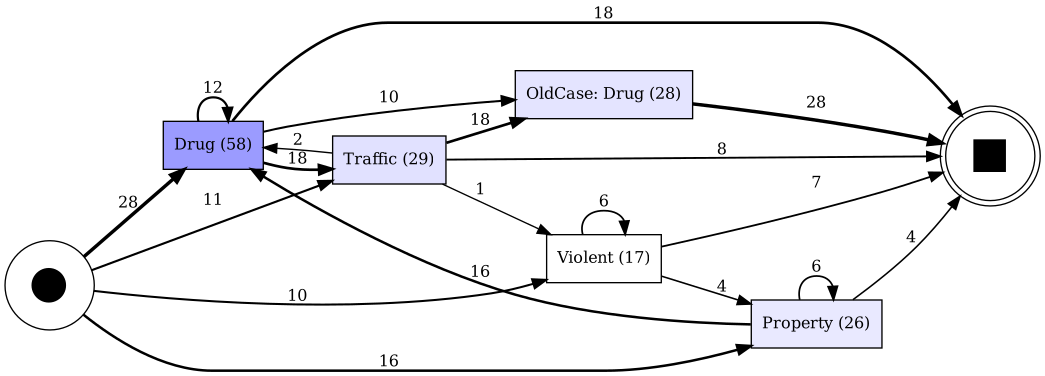

In [5]:
pm4py.save_vis_dfg(dfg, start_acts, end_acts, str(FIG / "dfg_frequency.png"))
show(FIG / "dfg_frequency.png")

**Как читать.**
- Толщина и число на дуге — частота. Самые толстые дуги — главные переходы процесса: здесь `Drug → Traffic` (18) и
  `Traffic → OldCase: Drug` (18).
- Число в вершине — сколько раз активность встречается в журнале.
- **Петля** `A → A` (дуга в саму себя): у человека подряд два события одной категории. Здесь `Violent → Violent`
  (6 человек сели дважды за насилие) и `Property → Property`. В варианте x2 петля `X → X` означает **новое** дело той
  же категории, а повторное заключение по тому же делу уходит в `X → OldCase: X`.
- **Осторожно с дугами внутри заключения**: `Drug → Traffic` — это не «после наркотиков человек совершил
  правонарушение на дороге», а две категории одного заключения, упорядоченные по тяжести. По одному DFG эти два
  случая не различить — нужна таблица шагов (раздел 4).
- Из-за того же порядка `Traffic → OldCase: Drug` (18) — артефакт: после заключения `{Drug, Traffic}` человек снова
  сел по старому делу о наркотиках, но последним событием заключения был Traffic, и дуга пошла из него. Прямая дуга
  `Drug → OldCase: Drug` (10) — только у тех, у кого в заключении был один Drug.
- Частота дуги ничего не говорит о **вероятности**: чтобы получить `P(B | A)`, частоту дуги делят на сумму частот
  всех дуг, выходящих из `A` (плюс число трасс, которые на `A` закончились).

### Фильтр путей

Когда дуг сотни, рисунок нечитаем. `pm4py.filter_dfg_paths_percentage(dfg, sa, ea, p)` оставляет самые частые дуги,
которые покрывают долю `p` всех путей, и только связанные с ними активности. В основном ноутбуке `p = 0.3`.

p = 0.3: дуг 3 из 10: [('Drug', 'Traffic'), ('Traffic', 'OldCase: Drug'), ('Property', 'Drug')]
p = 0.6: дуг 5 из 10: [('Drug', 'Traffic'), ('Traffic', 'OldCase: Drug'), ('Property', 'Drug'), ('Drug', 'Drug'), ('Drug', 'OldCase: Drug')]
p = 1.0: дуг 10 из 10: [('Drug', 'Traffic'), ('Traffic', 'OldCase: Drug'), ('Property', 'Drug'), ('Drug', 'Drug'), ('Drug', 'OldCase: Drug'), ('Property', 'Property'), ('Violent', 'Violent'), ('Violent', 'Property'), ('Traffic', 'Drug'), ('Traffic', 'Violent')]


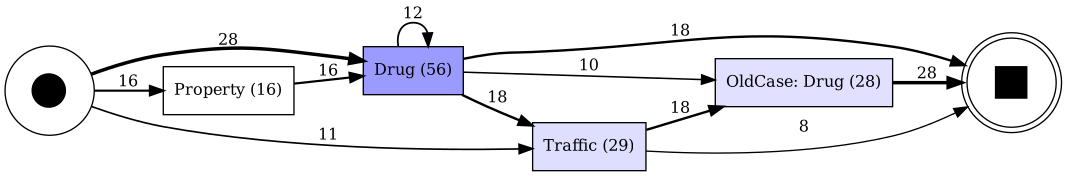

In [6]:
for p in (0.3, 0.6, 1.0):
    d_f, sa_f, ea_f = pm4py.filter_dfg_paths_percentage(dfg, start_acts, end_acts, p)
    print(f"p = {p}: дуг {len(d_f)} из {len(dfg)}:", sorted(d_f, key=d_f.get, reverse=True))
dfg_f, sa_f, ea_f = pm4py.filter_dfg_paths_percentage(dfg, start_acts, end_acts, 0.6)
# обход ошибки pm4py 2.7.23.9: после фильтра в начальных/конечных могут остаться активности, которых нет в дугах,
# и save_vis_dfg падает с KeyError — оставляем только активности, которые есть в отфильтрованном графе
acts_f = {a for k in dfg_f for a in k}
sa_f = {a: n for a, n in sa_f.items() if a in acts_f}
ea_f = {a: n for a, n in ea_f.items() if a in acts_f}
pm4py.save_vis_dfg(dfg_f, sa_f, ea_f, str(FIG / "dfg_frequency_paths60.png"))
show(FIG / "dfg_frequency_paths60.png")

**Как читать отфильтрованный граф.** Он показывает «скелет» процесса, но не всё: редкие пути (`Traffic → Violent`)
и даже не очень редкие исчезают. Выводы о том, **чего нет** в процессе, по отфильтрованному графу делать нельзя —
только по полной таблице дуг.

**Особенность pm4py 2.7.23.9.** `save_vis_dfg` падает с `KeyError` на сильно отфильтрованном графе
(в основном ноутбуке — на 10% путей; 30% работает). Причина: после фильтра в начальных или конечных активностях
остаётся активность, у которой не осталось ни одной дуги. Обход — в ячейке выше: убрать такие активности из `sa_f`
и `ea_f` перед рисованием.

**В нашем ноутбуке.** У x2 543 дуги (у трёх других вариантов 177–203): каждая категория удвоилась, и появились дуги
`X → OldCase: X`. Поэтому рисунок — только для 30% путей, а все дуги полного графа лежат в `out/dfg_arcs_x2.csv`;
анализировать лучше эту таблицу.

## 3. DFG времён (подшаг 4.3)

**Что это.** Тот же граф, но на дуге не частота, а **время перехода** `A → B` — медиана (или среднее, минимум,
максимум) по всем парам «`A`, сразу за ним `B`».

**Зачем.** Частота говорит, *куда* люди переходят, время — *как быстро*. Для нашей цели (конкурирующие риски) время
до следующего события — главная величина: по нему потом строятся кривые выживаемости и интенсивности переходов.

### 3.1. Стандартный способ PM4Py: от метки до метки

`pm4py.discover_performance_dfg` берёт одну метку времени на событие и считает `время(B) − время(A)`. У нас метка —
вход в заключение, так что получается время **«вход → вход»**: срок в заключении плюс время на свободе.

In [7]:
perf_std, sa, ea = pm4py.discover_performance_dfg(log)
std = pd.DataFrame({k: {"медиана, дней": v["median"] / 86400, "среднее, дней": v["mean"] / 86400}
                    for k, v in perf_std.items()}).T.round(1)
std.index = [f"{a} → {b}" for a, b in std.index]
std.sort_values("медиана, дней")

,"медиана, дней","среднее, дней"
Drug → Traffic,0.0,0.0
Traffic → Drug,0.0,0.0
Traffic → OldCase: Drug,78.0,82.8
Drug → OldCase: Drug,80.0,77.0
Violent → Property,260.5,260.0
Drug → Drug,285.5,280.2
Violent → Violent,308.5,291.8
Property → Drug,322.0,312.3
Traffic → Violent,323.0,323.0
Property → Property,352.0,349.7


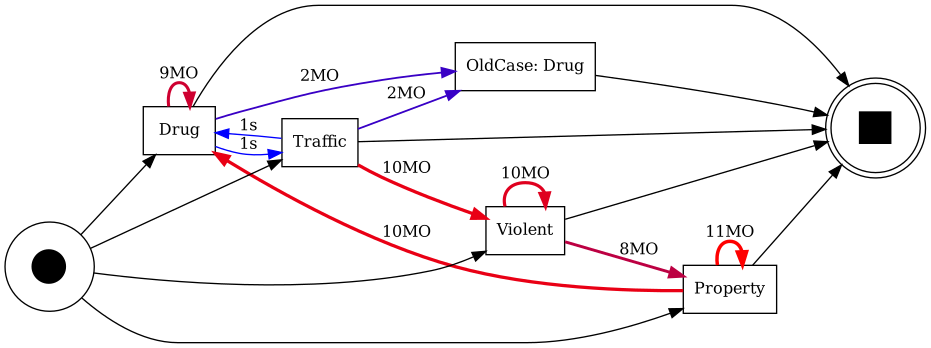

In [8]:
pm4py.save_vis_performance_dfg(perf_std, sa, ea, str(FIG / "dfg_performance_standard.png"),
                               aggregation_measure="median")
show(FIG / "dfg_performance_standard.png")

Дуги внутри одного заключения (`Drug → Traffic`) получили 1 секунду — это наш искусственный сдвиг для порядка.

### 3.2. Как в нашем ноутбуке: время на свободе

**Время перехода между заключениями = время на свободе**: от выхода из предыдущего заключения (`out_custody` у `A`)
до входа в следующее (`in_custody` у `B`). Срок в заключении в него не входит: новое преступление (и новое
заключение) возможно только на свободе, и в анализе выживаемости время до события считают именно так — человек «под
риском» только на свободе. Внутри одного заключения время = 0.

Пример: сидел с 1 января по 1 марта, снова сел 1 июня → на дуге 1 марта → 1 июня ≈ 92 дня, а не 1 января → 1 июня
≈ 151 день.

PM4Py не умеет считать время между двумя *разными* колонками (выход у `A`, вход у `B`), поэтому времена считаются
вручную по тем же парам соседних событий, что и DFG, и в нужном формате передаются в рисовалку PM4Py —
ровно так, как в основном ноутбуке.

In [9]:
e = log.sort_values(["case:concept:name", "time:timestamp"]).reset_index(drop=True)
nx = e.groupby("case:concept:name").shift(-1)
m = nx["concept:name"].notna()
pairs = pd.DataFrame({"from": e.loc[m, "concept:name"].values, "to": nx.loc[m, "concept:name"].values,
                      "between": (nx.loc[m, "step"] != e.loc[m, "step"]).values})
free = (nx.loc[m, "in_custody"] - e.loc[m, "out_custody"]).dt.total_seconds().clip(lower=0).values
pairs["sec"] = np.where(pairs["between"], free, 0.0)                    # внутри заключения — 0
pairs["start_to_start_days"] = (nx.loc[m, "in_custody"] - e.loc[m, "in_custody"]).dt.days.values
assert len(pairs) == sum(dfg.values())                                  # те же пары, что у DFG

agg = pairs.groupby(["from", "to"])["sec"].agg(["mean", "median", "max", "min", "sum", "std"]).fillna(0)
perf_free = {k: {"mean": r["mean"], "median": r["median"], "max": r["max"], "min": r["min"],
                 "sum": r["sum"], "stdev": r["std"]} for k, r in agg.iterrows()}

cmp = pairs.groupby(["from", "to"]).agg(пар=("sec", "size"),
                                        медиана_на_свободе=("sec", lambda s: s.median() / 86400),
                                        медиана_вход_вход=("start_to_start_days", "median")).round(1)
cmp.index = [f"{a} → {b}" for a, b in cmp.index]
cmp.sort_values("медиана_на_свободе")

,пар,медиана_на_свободе,медиана_вход_вход
Drug → Traffic,18,0.0,0.0
Traffic → Drug,2,0.0,0.0
Drug → OldCase: Drug,10,36.5,80.0
Traffic → OldCase: Drug,18,37.5,78.0
Violent → Property,4,224.0,260.5
Drug → Drug,12,227.0,285.5
Traffic → Violent,1,237.0,323.0
Property → Drug,16,268.0,322.0
Violent → Violent,6,285.0,308.5
Property → Property,6,327.5,352.0


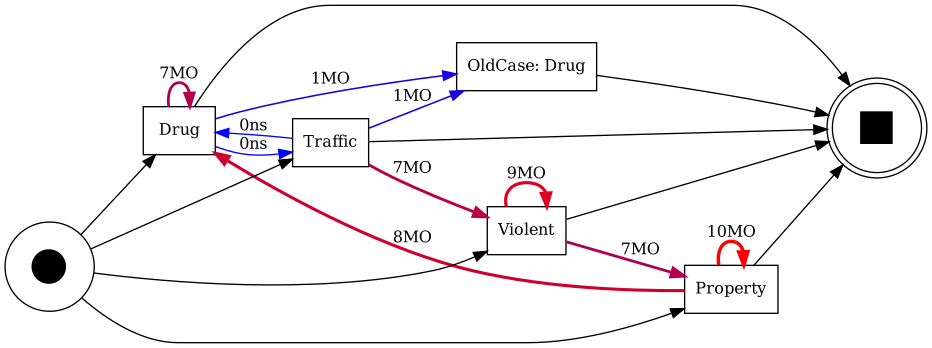

In [10]:
pm4py.save_vis_performance_dfg(perf_free, start_acts, end_acts, str(FIG / "dfg_performance_free.png"),
                               aggregation_measure="median")
show(FIG / "dfg_performance_free.png")

**Как читать.**
- Время на дуге — медиана (в PM4Py подписывается как `D` дни, `h` часы, `MO` месяцы). Цвет и толщина дуги в
  рисунке времён — от частоты, а не от времени.
- Сравните `Drug → OldCase: Drug` (по старому делу снова сажают быстро, медиана ~37 дней на свободе) и
  `Property → Drug` (новое дело, ~9 месяцев). Это и есть содержательная разница `X` и `OldCase: X`.
- В стандартном варианте те же дуги длиннее на срок заключения `A`; если сроки у категорий разные, сравнение
  категорий по «вход → вход» искажено.
- Медиана лучше среднего: распределение времени до повторного заключения сильно скошено вправо.
- **Ограничение DFG времён:** считаются только *наблюдённые* переходы. Люди, которые после `A` больше не сели
  (цензурированы), в эти медианы не входят, поэтому медиана на дуге — это «время до перехода среди тех, кто
  перешёл». Цензуру учитывает уже анализ выживаемости (следующие шаги плана), а не PM4Py.

**В нашем ноутбуке.** Медиана по 11 136 переходам между заключениями — 124 дня на свободе (от входа до входа было бы
157). Таблица по дугам — `out/dfg_times_free_x2.csv`. 75 переходов с отрицательным интервалом (следующее
заключение началось раньше, чем закончилось предыдущее) приравнены к 0.

## 4. Матрица переходов между шагами (подшаг 4.4)

**Что это.** Таблица `P[A, B]` = оценка вероятности, что следующим состоянием после `A` будет `B`. Строки — текущее
состояние, столбцы — следующее, каждая строка в сумме = 1. Это матрица переходов марковской цепи.

**Зачем.** DFG смешивает переходы *внутри* заключения и *между* заключениями. Матрица считается по **шагам**
(заключениям): переход — это только «заключение k → заключение k+1» одного человека. Это заготовка для шага 5 плана:
в конкурирующих рисках матрица даёт, *какой* из рисков сработает, а время на свободе — *когда*.

**Как строится, если в шаге несколько категорий.** Шаг `S_k` — набор категорий. Переход `S_k → S_{k+1}` — одно
событие, его вес 1 делится поровну на все пары категорий: каждой паре `(x, y)`, `x ∈ S_k`, `y ∈ S_{k+1}`
достаётся `1 / (|S_k| · |S_{k+1}|)`. Потом веса суммируются и каждая строка делится на свою сумму.

Пример: `{Drug} → {Drug, Traffic}`: пары `Drug→Drug` и `Drug→Traffic` получают по 1/(1·2) = 0.5.
`{Drug, Traffic} → {OldCase: Drug}`: пары `Drug→OldCase: Drug` и `Traffic→OldCase: Drug` — по 0.5.

In [11]:
s = st.sort_values(["id", "step"]).copy()
s["next_types"] = s.groupby("id")["types"].shift(-1)
tr = s[s["next_types"].notna()]
rows = []
for a, b in zip(tr["types"], tr["next_types"]):
    w = 1.0 / (len(a) * len(b))
    rows += [(x, y, w) for x in a for y in b]
W = pd.DataFrame(rows, columns=["from", "to", "w"]).pivot_table(index="from", columns="to", values="w",
                                                                 aggfunc="sum", fill_value=0)
order = ["Drug", "OldCase: Drug", "Property", "Traffic", "Violent"]
W = W.reindex(index=order, columns=order, fill_value=0)
P = W.div(W.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)
print("переходов между шагами:", len(tr))
print("взвешенные числа переходов W:"); display(W.round(2))
print("вероятности P (строки в сумме 1):"); display(P.round(2))

переходов между шагами: 73
взвешенные числа переходов W:


to,Drug,OldCase: Drug,Property,Traffic,Violent
from,,,,,
Drug,6.0,19.0,0.0,6.0,0.0
OldCase: Drug,0.0,0.0,0.0,0.0,0.0
Property,16.0,0.0,6.0,0.0,0.0
Traffic,0.0,9.0,0.0,0.0,1.0
Violent,0.0,0.0,4.0,0.0,6.0


вероятности P (строки в сумме 1):


to,Drug,OldCase: Drug,Property,Traffic,Violent
from,,,,,
Drug,0.19,0.61,0.00,0.19,0.0
OldCase: Drug,0.00,0.00,0.00,0.00,0.0
Property,0.73,0.00,0.27,0.00,0.0
Traffic,0.00,0.90,0.00,0.00,0.1
Violent,0.00,0.00,0.40,0.00,0.6


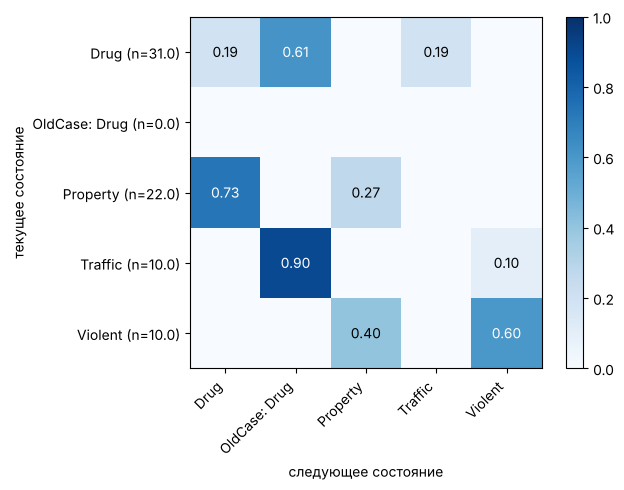

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 5))
im_ = ax.imshow(P.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(order)), order, rotation=45, ha="right")
ax.set_yticks(range(len(order)), [f"{a} (n={W.loc[a].sum():.1f})" for a in order])
for i in range(len(order)):
    for j in range(len(order)):
        if P.values[i, j] > 0:
            ax.text(j, i, f"{P.values[i, j]:.2f}", ha="center", va="center",
                    color="white" if P.values[i, j] > 0.5 else "black")
ax.set_xlabel("следующее состояние"); ax.set_ylabel("текущее состояние")
fig.colorbar(im_, ax=ax, fraction=0.04); fig.tight_layout()
fig.savefig(FIG / "transition_matrix.png", dpi=120); plt.show()

**Как читать.**
- Строка `Drug`: из заключения с Drug следующим чаще всего идёт `OldCase: Drug` — повторное заключение по тому же
  делу, — затем `Drug` и `Traffic` (снова новое дело).
- Диагональ — петли (то же состояние снова). В DFG `Drug → Traffic` было 18 раз, а в матрице вес `Drug → Traffic`
  всего 6: пары внутри одного заключения матрица не считает, остаются только переходы `{Drug} → {Drug, Traffic}`
  (12 человек × 0.5).
- Артефакт DFG `Traffic → OldCase: Drug` (18) здесь исправлен: переход `{Drug, Traffic} → {OldCase: Drug}` делит вес
  поровну, и `Drug → OldCase: Drug` получает 19 (10 + 18 × 0.5), `Traffic → OldCase: Drug` — 9.
- Строка `OldCase: Drug` пустая: в игрушечном журнале после старого дела никто больше не сел. Строку без переходов
  нельзя читать как «вероятность 0» — это нет данных.
- `n` у строки — сколько (взвешенных) переходов из состояния; маленькое `n` — ненадёжная строка.
- Матрица не учитывает людей, которые после шага больше не сели (цензура), — это, опять же, задача модели
  конкурирующих рисков.

**В нашем ноутбуке.** Самые сильные переходы — повторы по старому делу (`OldCase: Drug → OldCase: Drug` 0.47), затем
`X → OldCase: X` (Drug 0.33), настоящие петли по новым делам — около 0.2. Файлы `transition_probs_x2.csv` и
`transition_weighted_counts_x2.csv`.

## 5. Heuristics Miner (подшаг 4.5)

**Что это.** Алгоритм *process discovery* — построения модели процесса по журналу. Он берёт DFG и выбрасывает
«ненадёжные» дуги. Для каждой пары считается **мера зависимости**

$$a \Rightarrow b = \frac{|a>b| - |b>a|}{|a>b| + |b>a| + 1}$$

где `|a>b|` — частота дуги `a → b` из DFG. Мера от −1 до 1: близко к 1 — `b` почти всегда идёт после `a` и почти
никогда наоборот, то есть настоящая причинная связь «`a`, потом `b`»; около 0 — порядок случайный. Для петли
`a → a`: `|a>a| / (|a>a| + 1)`. Дуга остаётся, если мера ≥ `dependency_threshold`. Единица в знаменателе штрафует
редкие дуги: дуга, встреченная 1 раз, получает 0.5, 9 раз — 0.9.

**Зачем.** DFG показывает всё, включая шум и случайный порядок. Heuristics Miner оставляет устойчивые связи и
устойчив к шуму, поэтому для «грязных» реальных данных он — стандартный первый выбор. Результат — эвристическая
сеть, которую можно перевести в сеть Петри (раздел 6) и проверить на качество (раздел 8).

**Как строится.** Посчитаем меру вручную и сравним с PM4Py при порогах 0.9 и 0.5.

In [13]:
acts = sorted(log["concept:name"].unique())
dep = []
for a in acts:
    for b in acts:
        ab, ba = dfg.get((a, b), 0), dfg.get((b, a), 0)
        if ab == 0:
            continue
        d = ab / (ab + 1) if a == b else (ab - ba) / (ab + ba + 1)
        dep.append({"дуга": f"{a} → {b}", "|a>b|": ab, "|b>a|": ba, "зависимость": round(d, 3),
                    "порог 0.9": d >= 0.9, "порог 0.5": d >= 0.5})
pd.DataFrame(dep).sort_values("зависимость", ascending=False)

,дуга,|a>b|,|b>a|,зависимость,порог 0.9,порог 0.5
6,Traffic → OldCase: Drug,18,0,0.947,True,True
3,Property → Drug,16,0,0.941,True,True
0,Drug → Drug,12,12,0.923,True,True
1,Drug → OldCase: Drug,10,0,0.909,True,True
9,Violent → Violent,6,6,0.857,False,True
4,Property → Property,6,6,0.857,False,True
8,Violent → Property,4,0,0.800,False,True
2,Drug → Traffic,18,2,0.762,False,True
7,Traffic → Violent,1,0,0.500,False,True
5,Traffic → Drug,2,18,-0.762,False,False


Например, `Drug → Traffic` встречается 18 раз, но и `Traffic → Drug` — 2 раза (заключения, где Traffic был тяжелее),
поэтому мера (18 − 2)/(18 + 2 + 1) = 0.76: при пороге 0.9 дуга исчезнет, при 0.5 останется.
`Traffic → Violent` (1 раз): 1/2 = 0.5 — шум, отсеется при 0.9. У петли `Drug → Drug` столбец `|b>a|` совпадает с
`|a>b|` (это та же дуга), считается по формуле для петли: 12/13 = 0.92.

порог 0.9:


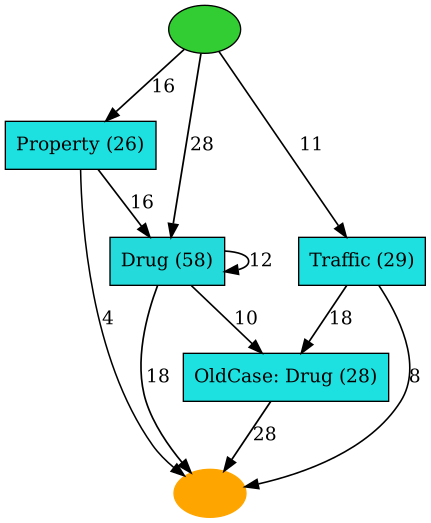

порог 0.5:


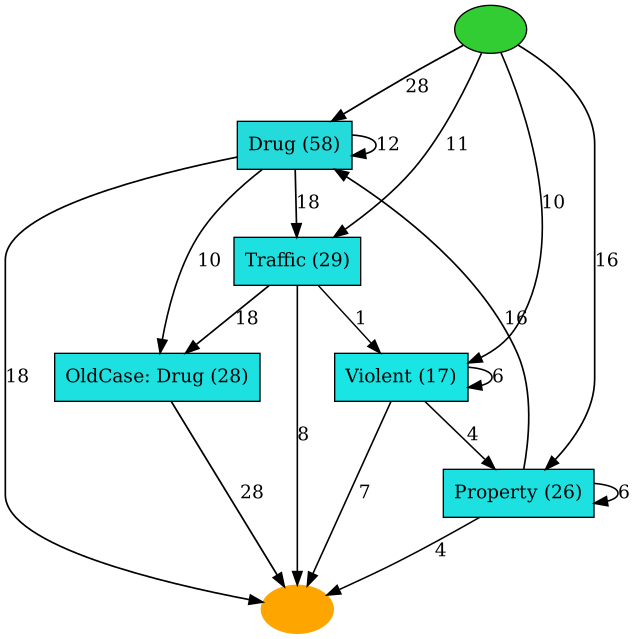

In [14]:
for d in (0.9, 0.5):
    hn = pm4py.discover_heuristics_net(log, dependency_threshold=d)
    pm4py.save_vis_heuristics_net(hn, str(FIG / f"heuristics_net_dep{d}.png"))
    print(f"порог {d}:"); show(FIG / f"heuristics_net_dep{d}.png", width=520)

**Как читать эвристическую сеть.**
- Прямоугольник — активность, число в нём — сколько раз она встретилась.
- Число на дуге — частота `|a>b|` (у дуг, прошедших порог). Дуги идут от начального кружка и к конечному.
- Чем выше порог, тем меньше дуг: остаются только связи с явным направлением и достаточной частотой.
  При 0.9 пропали `Drug → Traffic`, `Traffic → Violent`, `Violent → Property` и петли `Property → Property`,
  `Violent → Violent` (6/7 = 0.86). У `Violent` не осталось ни одной дуги, и он исчез из модели совсем: 10 человек с
  Violent эта модель не воспроизведёт. Так на маленьком журнале выглядит цена высокого порога.
- Выбор порога — компромисс: высокий порог даёт простую модель, которая может не воспроизвести часть трасс
  (fitness падает), низкий — сложную, которая разрешает больше лишнего.

Дальше та же модель как сеть Петри — так её можно проверять на качество.

## 6. Сеть Петри (в 4.5 и 4.6)

**Что это.** Формальная модель процесса из двух видов вершин:
- **переход** (transition, прямоугольник) — активность, например `Drug`;
- **место** (place, кружок) — «условие» или «состояние ожидания» между активностями.

Дуги идут только место → переход или переход → место. По местам ходят **фишки** (tokens). Переход может
**сработать**, если во всех его входных местах есть фишка; при срабатывании он забирает по фишке из входных мест и
кладёт по фишке в выходные. **Начальная разметка** (initial marking, `im`) — где фишки в начале (одна фишка в
месте «старт»), **конечная** (final marking, `fm`) — где они должны оказаться в конце. Трасса *подходит* модели, если
её активности можно сработать по очереди от `im` до `fm`.

**Скрытые (silent, τ) переходы** — чёрные прямоугольники без подписи: они ничего не означают в журнале, только
«переключают» фишки (например, чтобы пропустить активность или выйти из цикла).

**Зачем.** DFG и эвристическая сеть — картинки; сеть Петри — модель с точной семантикой: про любую трассу можно
вычислить, может ли модель её породить. На этом построены проверки fitness и precision (раздел 8). Ещё одна причина:
в плане диплома переходы между состояниями моделируются именно как граф/сеть Петри поверх повторяющихся состояний.

HM 0.9: мест 6, переходов 10 (скрытых 6), дуг 21
начальная разметка: ['source0:1'] | конечная: ['sink0:1']


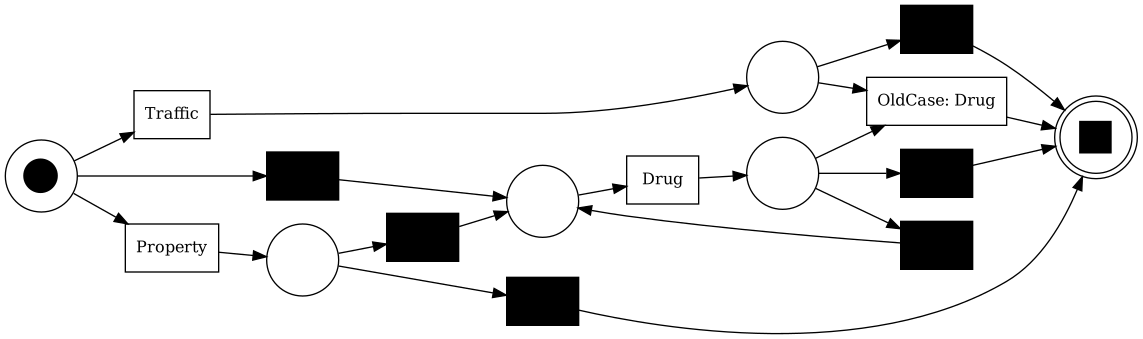

In [15]:
net_hm, im_hm, fm_hm = pm4py.discover_petri_net_heuristics(log, dependency_threshold=0.9)
pm4py.save_vis_petri_net(net_hm, im_hm, fm_hm, str(FIG / "petri_HM_dep0.9.png"))
print(f"HM 0.9: мест {len(net_hm.places)}, переходов {len(net_hm.transitions)} "
      f"(скрытых {sum(t.label is None for t in net_hm.transitions)}), дуг {len(net_hm.arcs)}")
print("начальная разметка:", im_hm, "| конечная:", fm_hm)
show(FIG / "petri_HM_dep0.9.png")

**Как читать.** Найдите место с фишкой (чёрная точка в кружке) — это старт; место с двойным кругом — конец.
Пройдите путь фишкой. Из старта три выхода — *выбор* (XOR, сработает ровно один): переход `Traffic`, переход
`Property` или скрытый переход сразу к месту перед `Drug`. После `Drug` фишка попадает в место с тремя выходами:
`OldCase: Drug`, скрытый переход к концу или скрытый переход назад, к месту перед `Drug` — это **цикл**, он
позволяет `Drug → Drug`. После `Traffic` можно только `OldCase: Drug` или конец: дуги `Drug → Traffic` в модели
нет. `Violent` в модели нет вовсе (см. раздел 5). Чёрные переходы — скрытые: позволяют пропустить активность или
вернуться назад. Если бы у перехода были две выходные дуги в разные места, это была бы *параллельность* (AND): обе
ветви должны пройти.

Сети Heuristics Miner **не всегда корректны** (sound): могут быть ситуации, где фишка «застревает» и конец
недостижим. Отсюда трассы, которые модель не воспроизводит, и fitness < 1.

## 7. Inductive Miner и дерево процесса (подшаг 4.6)

**Что это.** Inductive Miner тоже строит модель по журналу, но иначе: он рекурсивно **режет** множество активностей на
части по DFG и каждый раз выбирает, как части связаны. Результат — **дерево процесса** (process tree):
листья — активности (или `τ` — «ничего»), внутренние узлы — операторы:

| оператор | обозначение | смысл |
|---|---|---|
| последовательность | `→` (seq) | дети по очереди, слева направо |
| исключающий выбор | `X` (xor) | ровно один из детей |
| параллельность | `+` (and) | все дети, в любом порядке / вперемешку |
| цикл | `*` (loop) | первый ребёнок, затем сколько угодно раз «второй ребёнок, снова первый» |

Например `→( X(Drug, Property), X(τ, OldCase: Drug) )` читается так: «сначала Drug или Property, потом,
возможно, OldCase: Drug».

Из дерева однозначно получается сеть Петри, и она **гарантированно корректна** (sound): из старта всегда можно
дойти до конца. **Порог шума** `noise_threshold` (0…1) — какую долю редкого поведения игнорировать при разрезании:
0 — модель воспроизводит **все** трассы журнала (fitness = 1), но обычно очень обобщённая; 0.2 (как в основном
ноутбуке) — отбрасывает редкие связи.

**Зачем.** Гарантия корректности и полного воспроизведения журнала (при 0) — это опорная модель для сравнения с
Heuristics Miner. Цена — Inductive Miner легко «обобщает»: если порядок не очевиден, он ставит цикл или
параллельность, и модель разрешает много путей, которых в данных не было (низкая precision).

порог шума 0.0: ->( +( X( tau, *( 'Drug', tau ) ), X( tau, ->( X( tau, 'Traffic' ), X( tau, *( 'Violent', tau ) ), X( tau, *( 'Property', tau ) ) ) ) ), X( tau, 'OldCase: Drug' ) )


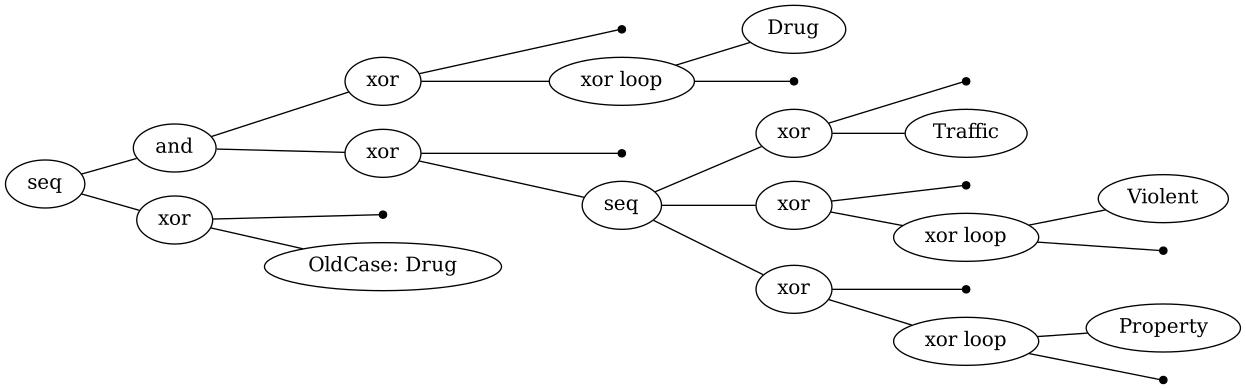

порог шума 0.2: ->( X( tau, *( 'Violent', tau ) ), X( tau, *( 'Property', tau ) ), X( tau, *( 'Drug', tau ) ), X( tau, 'Traffic' ), X( tau, 'OldCase: Drug' ) )


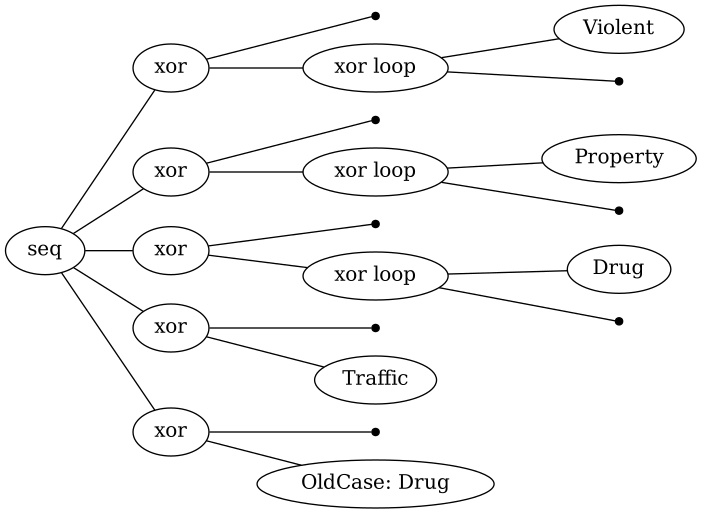

In [16]:
for nt in (0.0, 0.2):
    tree = pm4py.discover_process_tree_inductive(log, noise_threshold=nt)
    print(f"порог шума {nt}:", tree)
    pm4py.save_vis_process_tree(tree, str(FIG / f"process_tree_IM_noise{nt}.png"))
    show(FIG / f"process_tree_IM_noise{nt}.png", width=600)

IM 0.2: мест 13, переходов 20 (скрытых 15)


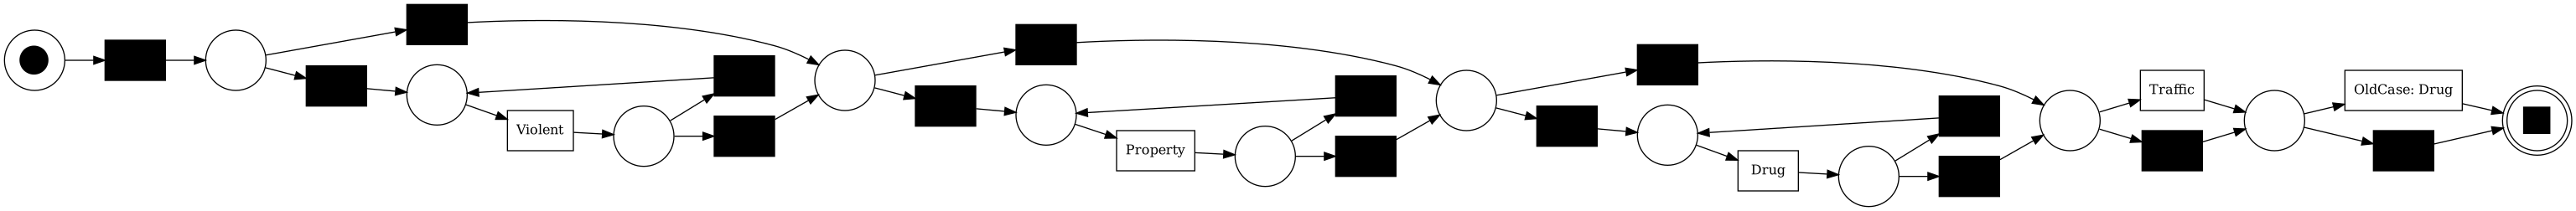

In [17]:
tree = pm4py.discover_process_tree_inductive(log, noise_threshold=0.2)
net_im, im_im, fm_im = pm4py.convert_to_petri_net(tree)
pm4py.save_vis_petri_net(net_im, im_im, fm_im, str(FIG / "petri_IM_noise0.2.png"))
print(f"IM 0.2: мест {len(net_im.places)}, переходов {len(net_im.transitions)} "
      f"(скрытых {sum(t.label is None for t in net_im.transitions)})")
show(FIG / "petri_IM_noise0.2.png")

**Как читать дерево.** Читайте сверху вниз, корень — весь процесс. Дерево при пороге 0.2 текстом:
`->( X(tau, *(Violent, tau)), X(tau, *(Property, tau)), X(tau, *(Drug, tau)), X(tau, Traffic), X(tau, OldCase: Drug) )`
— «по порядку: сколько-то раз Violent (или ни разу), сколько-то раз Property, сколько-то раз Drug, может быть
Traffic, может быть OldCase: Drug». Оно разрешает и `Violent → Property → Drug → Traffic → OldCase: Drug`, которого
нет ни у кого: модель обобщила. При пороге 0 в дереве появляется `+` (параллельность): IM не нашёл порядка между
`Drug` и остальными и разрешил любой. В общем случае ищите:
- `*` (цикл) над активностями — модель говорит «эти состояния повторяются сколько угодно раз в любом порядке»;
  для нашего процесса (повторные заключения) это ожидаемо, но означает, что порядок переходов модель **не различает**;
- `X` с `τ` — необязательная часть (может быть, а может не быть);
- `+` — части, порядок между которыми модель не фиксирует.

Строка `print(tree)` — то же дерево текстом: `->(...)` последовательность, `X(...)` выбор, `+(...)` параллельность,
`*(...)` цикл, `tau` — пустой шаг.

**В нашем ноутбуке.** IM 0.2 строит блок «новые категории в цикле → необязательные `OldCase: X` параллельно», то есть
почти не различает, в каком порядке идут переходы; отсюда высокая fitness (0.994) и низкая precision (0.383).

## 8. Качество модели: fitness, precision, F1 (подшаг 4.7)

Модель процесса оценивают по нескольким осям. В ноутбуке используются две главные.

**Fitness (соответствие)** — насколько модель **воспроизводит** трассы журнала. 1 — каждую трассу можно
«проиграть» по модели. Низкая fitness — модель запрещает то, что реально происходит.

**Precision (точность)** — насколько модель **не разрешает лишнего**. 1 — модель позволяет только то, что видно в
журнале. Низкая precision — модель «всеядная»: например, сеть-«цветок», где любая активность в любом порядке,
имеет fitness 1 и precision около 0.

Они тянут в разные стороны, поэтому смотрят на обе и иногда на их гармоническое среднее
**F1 = 2·fitness·precision / (fitness + precision)**.

### Token-based replay (проигрывание фишек)

Как считается fitness в ноутбуке. Каждая трасса «проигрывается» по сети Петри: фишка ставится в старт, активности
трассы срабатывают по очереди. Если для срабатывания не хватает фишки в каком-то месте, её **досоздают** и считают как
`missing`; если в конце в сети остались лишние фишки — `remaining`. Ещё считают `produced` (сколько фишек
положено) и `consumed` (сколько забрано). Для одной трассы

$$\text{fitness} = \tfrac12\Big(1 - \tfrac{missing}{consumed}\Big) + \tfrac12\Big(1 - \tfrac{remaining}{produced}\Big)$$

а для журнала те же числа суммируются по всем трассам. `percentage_of_fitting_traces` — доля трасс, проигранных
без единой ошибки.

**Precision через token replay (ETC)**: в каждом месте трассы (префиксе) сравнивается, какие активности модель
разрешает следующими и какие реально встречались в журнале после такого же префикса. Чем больше разрешённых, но ни
разу не виденных продолжений («утечек»), тем ниже precision.

*Выравнивания* (alignments) — более точный, но намного более медленный способ считать fitness; на 29 состояниях
они очень долгие, поэтому в основном ноутбуке не используются.

Посмотрим на поведение одной трассы. Возьмём модель HM 0.9 и трассу, которой в журнале нет: `Traffic → Drug →
Violent`.

In [18]:
# журнал из одной придуманной трассы
odd = pd.DataFrame({"case:concept:name": ["X1"] * 3, "concept:name": ["Traffic", "Drug", "Violent"],
                    "time:timestamp": pd.to_datetime(["2015-01-01", "2015-06-01", "2016-01-01"])})
odd = pm4py.format_dataframe(odd, case_id="case:concept:name", activity_key="concept:name",
                             timestamp_key="time:timestamp")
diag = pm4py.conformance_diagnostics_token_based_replay(odd, net_hm, im_hm, fm_hm)[0]
print({k: diag[k] for k in ("trace_is_fit", "trace_fitness", "missing_tokens", "consumed_tokens",
                            "remaining_tokens", "produced_tokens", "transitions_with_problems")})
m_, c_, r_, p_ = diag["missing_tokens"], diag["consumed_tokens"], diag["remaining_tokens"], diag["produced_tokens"]
print("по формуле:", round(0.5 * (1 - m_ / c_) + 0.5 * (1 - r_ / p_), 4))

# трассы из журнала: P13 (Property → Drug) и P01 (Drug → Drug → Traffic → OldCase: Drug)
for pid in ("P13", "P01"):
    d = pm4py.conformance_diagnostics_token_based_replay(log[log["case:concept:name"] == pid], net_hm, im_hm, fm_hm)[0]
    print(pid, {k: d[k] for k in ("trace_is_fit", "trace_fitness", "missing_tokens", "remaining_tokens")})

{'trace_is_fit': False, 'trace_fitness': 0.75, 'missing_tokens': 1, 'consumed_tokens': 4, 'remaining_tokens': 1, 'produced_tokens': 4, 'transitions_with_problems': [(Drug, 'Drug')]}
по формуле: 0.75
P13 {'trace_is_fit': True, 'trace_fitness': 1.0, 'missing_tokens': 0, 'remaining_tokens': 0}
P01 {'trace_is_fit': False, 'trace_fitness': 0.9375, 'missing_tokens': 1, 'remaining_tokens': 0}


**Как читать.** У придуманной трассы `Drug` после `Traffic` модель не разрешает: для `Drug` не хватило фишки
(`missing = 1`, поле `transitions_with_problems`), а фишка, которую положил `Traffic`, так и осталась лежать
(`remaining = 1`). `Violent` в модели нет вовсе, и token replay такое событие просто пропускает (оно не штрафуется —
ещё одна причина смотреть на precision и на долю идеально проигранных трасс). Итог:
fitness = ½(1 − 1/4) + ½(1 − 1/4) = 0.75. `P13` проигрывается
идеально. А `P01`, хотя она есть в журнале, — нет: дугу `Drug → Traffic` HM 0.9 выбросил (раздел 5), поэтому
fitness 0.94. Так и получается fitness < 1 у Heuristics Miner на реальных данных.

### Обучение и проверка (train / test)

Модель, проверенная на тех же данных, на которых построена, выглядит лучше, чем она есть. Поэтому в ноутбуке люди
делятся случайно (seed 42) на **train** (80%) и **test** (20%): модель строится на train, fitness и precision
считаются на test. Если на test fitness заметно ниже, чем на train, модель переобучилась под конкретные трассы.

Ниже — то же самое на игрушечном журнале (людей мало, так что числа шумные — смотрим только на механику).

In [19]:
rng = np.random.default_rng(42)
ids = log["case:concept:name"].unique()
test_ids = set(rng.choice(ids, size=int(0.2 * len(ids)), replace=False))
train = log[~log["case:concept:name"].isin(test_ids)]
test = log[log["case:concept:name"].isin(test_ids)]

models = {f"HM_dep{d}": pm4py.discover_petri_net_heuristics(train, dependency_threshold=d) for d in (0.5, 0.9)}
models.update({f"IM_noise{nt}": pm4py.discover_petri_net_inductive(train, noise_threshold=nt) for nt in (0.0, 0.2)})
q = []
for name, (net, im, fm) in models.items():
    for split, lg in (("train", train), ("test", test)):
        fit = pm4py.fitness_token_based_replay(lg, net, im, fm)
        prec = pm4py.precision_token_based_replay(lg, net, im, fm)
        q.append(dict(model=name, split=split, cases=lg["case:concept:name"].nunique(),
                      fitness_tbr=round(fit["log_fitness"], 3),
                      pct_fit_traces=round(fit["percentage_of_fitting_traces"], 1),
                      precision_etc=round(prec, 3),
                      f1=round(2 * fit["log_fitness"] * prec / (fit["log_fitness"] + prec), 3),
                      places=len(net.places), transitions=len(net.transitions),
                      silent=sum(t.label is None for t in net.transitions)))
pd.DataFrame(q)

,model,split,cases,fitness_tbr,pct_fit_traces,precision_etc,f1,places,transitions,silent
0,HM_dep0.5,train,52,0.978,73.1,0.895,0.935,11,21,16
1,HM_dep0.5,test,13,0.970,69.2,0.883,0.924,11,21,16
2,HM_dep0.9,train,52,0.904,51.9,0.862,0.882,7,12,8
3,HM_dep0.9,test,13,0.885,46.2,0.828,0.856,7,12,8
4,IM_noise0.0,train,52,1.000,100.0,0.614,0.761,15,22,17
5,IM_noise0.0,test,13,1.000,100.0,0.613,0.760,15,22,17
6,IM_noise0.2,train,52,0.996,96.2,0.724,0.839,13,20,15
7,IM_noise0.2,test,13,0.992,92.3,0.680,0.807,13,20,15


**Как читать таблицу качества.**
- `fitness_tbr` — fitness по token replay (0…1); `pct_fit_traces` — % трасс, проигранных без ошибок (строже).
- `precision_etc` — точность; `f1` — их баланс.
- `places`, `transitions`, `silent` — размер модели. При равном качестве лучше модель проще.
- Здесь, как и в основном ноутбуке: IM с порогом 0 — fitness 1 и самая низкая precision (обобщает); HM точнее
  IM, но часть трасс не воспроизводит. HM 0.9 проще HM 0.5, но проигрывает ему и по fitness, и по precision:
  выброшенные дуги заменяются скрытыми переходами-обходами, которые разрешают лишнее. Сравнивайте строки `test`.

**В нашем ноутбуке** (test, 2 000 человек): HM 0.9 — fitness 0.982, precision 0.543; HM 0.5 — 0.942 / 0.614;
IM 0.2 — 0.994 / 0.383; IM 0.0 — 1.000 / 0.369. У варианта OldCase HM 0.9 давал 0.995 / 0.675: в x2 модели почти так
же хорошо воспроизводят трассы, но при 29 состояниях разрешают больше лишних путей. Расчёт запускается флагом
`RUN_EVAL = True` (2–3 минуты), иначе берётся готовый `out/model_quality_x2.csv`.

## Короткая шпаргалка

| понятие | отвечает на вопрос | главный подвох |
|---|---|---|
| DFG частот | какие переходы есть и сколько раз | дуги внутри заключения выглядят как переходы; фильтр прячет редкое |
| DFG времён | как быстро происходит переход | только наблюдённые переходы, без цензуры; считаем время на свободе вручную |
| матрица переходов | куда пойдёт человек со следующим заключением | строки с малым `n` ненадёжны; без цензуры |
| Heuristics Miner | какие связи устойчивы | порог; сеть может быть некорректной |
| Inductive Miner | корректная блочная модель | обобщает: циклы и параллельность → низкая precision |
| сеть Петри | формальная модель для проверки | читать через фишки, τ — служебные |
| fitness / precision | воспроизводит ли модель данные / не разрешает ли лишнего | тянут в разные стороны; смотреть на test |